## 1. Environment Setup and Dependencies

In [1]:
import os
import time
import json
import textwrap
import numpy as np
import tensorflow as tf
import matplotlib.pyplot as plt
import pandas as pd

from PIL import Image
from pathlib import Path
from skimage.metrics import structural_similarity as ssim
from IPython.display import display
from matplotlib.textpath import TextPath
from matplotlib.font_manager import FontProperties
from matplotlib.transforms import Bbox

## 2. Experiment Configuration and File Paths

In [2]:
CONTENT_PATH = "content_images/content.jpg"
STYLE_PATH = "style_images/style.jpg"

os.makedirs("outputs", exist_ok=True)
os.makedirs("logs", exist_ok=True)

## 3. Image Loading and Preprocessing

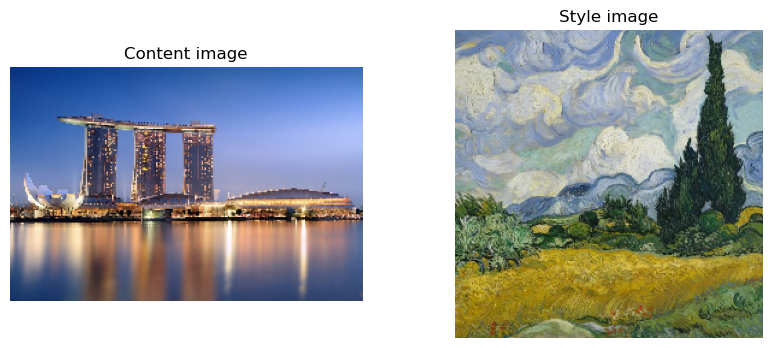

In [3]:
def load_image(path, max_dim=256):
    image = tf.io.read_file(path)
    image = tf.image.decode_image(image, channels=3)
    image = tf.image.convert_image_dtype(image, tf.float32)

    shape = tf.cast(tf.shape(image)[:-1], tf.float32)
    long_dim = max(shape)
    scale = max_dim / long_dim
    new_shape = tf.cast(shape * scale, tf.int32)

    image = tf.image.resize(image, new_shape)
    image = image[tf.newaxis, :]
    return image


def tensor_to_image(tensor):
    tensor = tensor * 255
    tensor = np.array(tensor, dtype=np.uint8)

    if tensor.ndim > 3:
        tensor = tensor[0]

    return Image.fromarray(tensor)


content_image = load_image(CONTENT_PATH, max_dim=256)
style_image = load_image(STYLE_PATH, max_dim=256)

plt.figure(figsize=(10, 4))

plt.subplot(1, 2, 1)
plt.imshow(tensor_to_image(content_image))
plt.title("Content image")
plt.axis("off")

plt.subplot(1, 2, 2)
plt.imshow(tensor_to_image(style_image))
plt.title("Style image")
plt.axis("off")

plt.show()

## 4. VGG19 Content and Style Feature Extraction

In [4]:
content_layers = ["block5_conv2"]

style_layers = [
    "block1_conv1",
    "block2_conv1",
    "block3_conv1",
    "block4_conv1",
    "block5_conv1"
]

num_content_layers = len(content_layers)
num_style_layers = len(style_layers)


def vgg_layers(layer_names):
    vgg = tf.keras.applications.VGG19(include_top=False, weights="imagenet")
    vgg.trainable = False

    outputs = [vgg.get_layer(name).output for name in layer_names]
    model = tf.keras.Model([vgg.input], outputs)
    return model


def gram_matrix(input_tensor):
    result = tf.linalg.einsum("bijc,bijd->bcd", input_tensor, input_tensor)
    input_shape = tf.shape(input_tensor)
    num_locations = tf.cast(input_shape[1] * input_shape[2], tf.float32)
    return result / num_locations


class StyleContentModel(tf.keras.models.Model):
    def __init__(self, style_layers, content_layers):
        super().__init__()
        self.vgg = vgg_layers(style_layers + content_layers)
        self.style_layers = style_layers
        self.content_layers = content_layers
        self.num_style_layers = len(style_layers)
        self.vgg.trainable = False

    def call(self, inputs):
        inputs = inputs * 255.0
        preprocessed_input = tf.keras.applications.vgg19.preprocess_input(inputs)
        outputs = self.vgg(preprocessed_input)

        style_outputs = outputs[:self.num_style_layers]
        content_outputs = outputs[self.num_style_layers:]

        style_outputs = [gram_matrix(style_output) for style_output in style_outputs]

        content_dict = {
            content_name: value
            for content_name, value in zip(self.content_layers, content_outputs)
        }

        style_dict = {
            style_name: value
            for style_name, value in zip(self.style_layers, style_outputs)
        }

        return {"content": content_dict, "style": style_dict}


extractor = StyleContentModel(style_layers, content_layers)

## 5. Neural Style Transfer Experiment Pipeline

In [5]:
def clip_0_1(image):
    return tf.clip_by_value(image, clip_value_min=0.0, clip_value_max=1.0)


def calculate_ssim(content_tensor, generated_tensor):
    content_np = np.array(tensor_to_image(content_tensor))
    generated_np = np.array(tensor_to_image(generated_tensor))

    return ssim(
        content_np,
        generated_np,
        channel_axis=2,
        data_range=255
    )


def run_experiment(
    content_path,
    style_path,
    run_id="baseline_run",
    image_size=256,
    style_weight=1e-2,
    content_weight=1e4,
    total_variation_weight=30,
    iterations=300
):
    start_time = time.time()

    content_image = load_image(content_path, max_dim=image_size)
    style_image = load_image(style_path, max_dim=image_size)

    style_targets = extractor(style_image)["style"]
    content_targets = extractor(content_image)["content"]

    generated_image = tf.Variable(content_image)

    optimizer = tf.keras.optimizers.Adam(learning_rate=0.02)

    loss_history = []

    for step in range(iterations):
        with tf.GradientTape() as tape:
            outputs = extractor(generated_image)

            style_outputs = outputs["style"]
            content_outputs = outputs["content"]

            style_loss = tf.add_n([
                tf.reduce_mean((style_outputs[name] - style_targets[name]) ** 2)
                for name in style_outputs.keys()
            ])
            style_loss *= style_weight / num_style_layers

            content_loss = tf.add_n([
                tf.reduce_mean((content_outputs[name] - content_targets[name]) ** 2)
                for name in content_outputs.keys()
            ])
            content_loss *= content_weight / num_content_layers

            tv_loss = total_variation_weight * tf.reduce_sum(
                tf.image.total_variation(generated_image)
            )

            total_loss = style_loss + content_loss + tv_loss

        gradients = tape.gradient(total_loss, generated_image)
        optimizer.apply_gradients([(gradients, generated_image)])
        generated_image.assign(clip_0_1(generated_image))

        if step % 50 == 0:
            loss_history.append({
                "step": step,
                "content_loss": float(content_loss),
                "style_loss": float(style_loss),
                "tv_loss": float(tv_loss),
                "total_loss": float(total_loss)
            })
            print(f"Step {step}: total loss = {float(total_loss):.2f}")

    runtime = time.time() - start_time

    output_path = f"outputs/{run_id}.png"
    tensor_to_image(generated_image).save(output_path)

    ssim_score = calculate_ssim(content_image, generated_image)

    result = {
        "run_id": run_id,
        "content_image": content_path,
        "style_image": style_path,
        "image_size": image_size,
        "style_weight": style_weight,
        "content_weight": content_weight,
        "total_variation_weight": total_variation_weight,
        "iterations": iterations,
        "runtime_seconds": runtime,
        "ssim_content_score": float(ssim_score),
        "final_content_loss": float(content_loss),
        "final_style_loss": float(style_loss),
        "final_tv_loss": float(tv_loss),
        "final_total_loss": float(total_loss),
        "output_path": output_path,
        "note": "Loss values are diagnostic only, not final image quality metrics."
    }

    log_path = f"logs/{run_id}.json"
    with open(log_path, "w") as f:
        json.dump(
            {"result": result, "loss_history": loss_history},
            f,
            indent=4
        )

    return generated_image, result, loss_history

## 6. Baseline Experiment

In [6]:
generated_image, result, loss_history = run_experiment(
    CONTENT_PATH,
    STYLE_PATH,
    run_id="baseline_run",
    image_size=256,
    style_weight=1e-2,
    content_weight=1e4,
    total_variation_weight=30,
    iterations=300
)

Step 0: total loss = 307494912.00
Step 50: total loss = 13935715.00
Step 100: total loss = 10413094.00
Step 150: total loss = 9150015.00
Step 200: total loss = 8479672.00
Step 250: total loss = 8065293.00


## 7. Baseline Output Visualisation

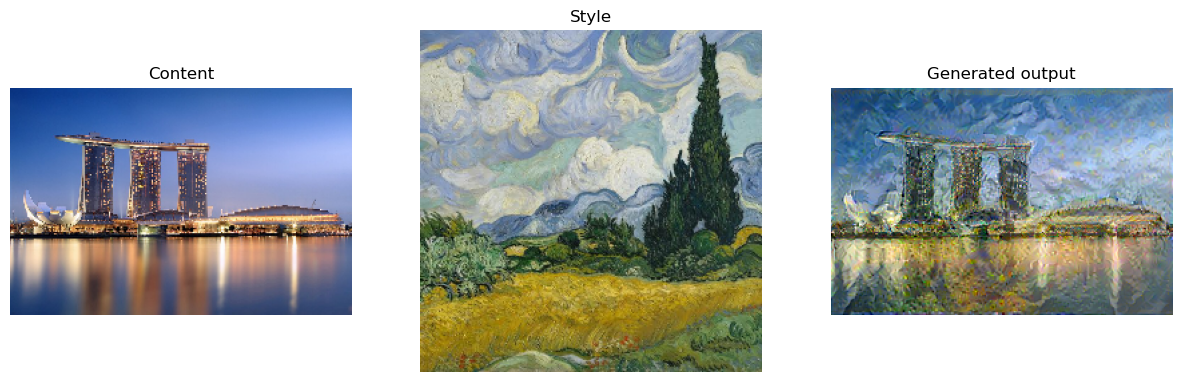

In [7]:
plt.figure(figsize=(15, 5))

plt.subplot(1, 3, 1)
plt.imshow(tensor_to_image(content_image))
plt.title("Content")
plt.axis("off")

plt.subplot(1, 3, 2)
plt.imshow(tensor_to_image(style_image))
plt.title("Style")
plt.axis("off")

plt.subplot(1, 3, 3)
plt.imshow(tensor_to_image(generated_image))
plt.title("Generated output")
plt.axis("off")

plt.show()

## 8. Baseline Experiment Results

In [8]:
result

{'run_id': 'baseline_run',
 'content_image': 'content_images/content.jpg',
 'style_image': 'style_images/style.jpg',
 'image_size': 256,
 'style_weight': 0.01,
 'content_weight': 10000.0,
 'total_variation_weight': 30,
 'iterations': 300,
 'runtime_seconds': 187.4897141456604,
 'ssim_content_score': 0.4001541524168288,
 'final_content_loss': 4477273.5,
 'final_style_loss': 2821178.25,
 'final_tv_loss': 482730.28125,
 'final_total_loss': 7781182.5,
 'output_path': 'outputs/baseline_run.png',
 'note': 'Loss values are diagnostic only, not final image quality metrics.'}

## 9. Optimisation Loss Analysis

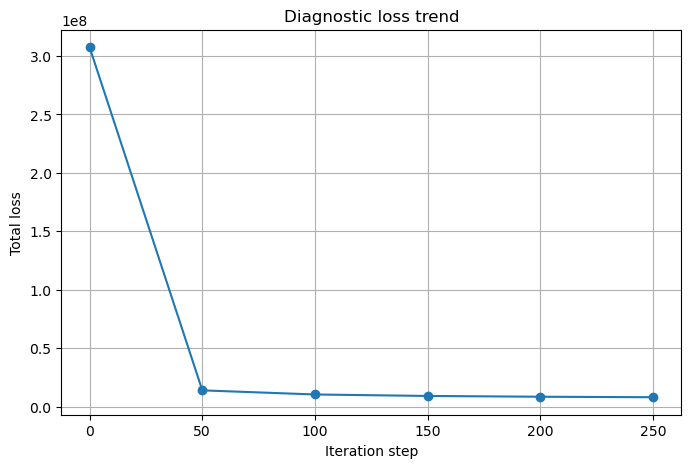

In [9]:
steps = [item["step"] for item in loss_history]
total_losses = [item["total_loss"] for item in loss_history]

plt.figure(figsize=(8, 5))
plt.plot(steps, total_losses, marker="o")
plt.xlabel("Iteration step")
plt.ylabel("Total loss")
plt.title("Diagnostic loss trend")
plt.grid(True)
plt.show()

## 10. Low Style-Weight Experiment

In [10]:
generated_low_style, result_low_style, loss_low_style = run_experiment(
    CONTENT_PATH,
    STYLE_PATH,
    run_id="low_style_weight",
    image_size=256,
    style_weight=1e-3,
    content_weight=1e4,
    total_variation_weight=30,
    iterations=300
)

Step 0: total loss = 30997394.00
Step 50: total loss = 4472916.00
Step 100: total loss = 3619067.75
Step 150: total loss = 3365575.00
Step 200: total loss = 3204338.25
Step 250: total loss = 3132644.75


## 11. High Style-Weight Experiment

In [11]:
generated_high_style, result_high_style, loss_high_style = run_experiment(
    CONTENT_PATH,
    STYLE_PATH,
    run_id="high_style_weight",
    image_size=256,
    style_weight=1e-1,
    content_weight=1e4,
    total_variation_weight=30,
    iterations=300
)

Step 0: total loss = 3072469760.00
Step 50: total loss = 54452544.00
Step 100: total loss = 36484424.00
Step 150: total loss = 30487750.00
Step 200: total loss = 27369810.00
Step 250: total loss = 25323320.00


## 12. Style-Weight Comparison

The three outputs below compare different style-weight settings while keeping the remaining baseline settings unchanged.

The full images show the overall effect of each setting, while the enlarged crops show the same region in greater detail. This makes changes in texture, structural preservation and style strength easier to identify.

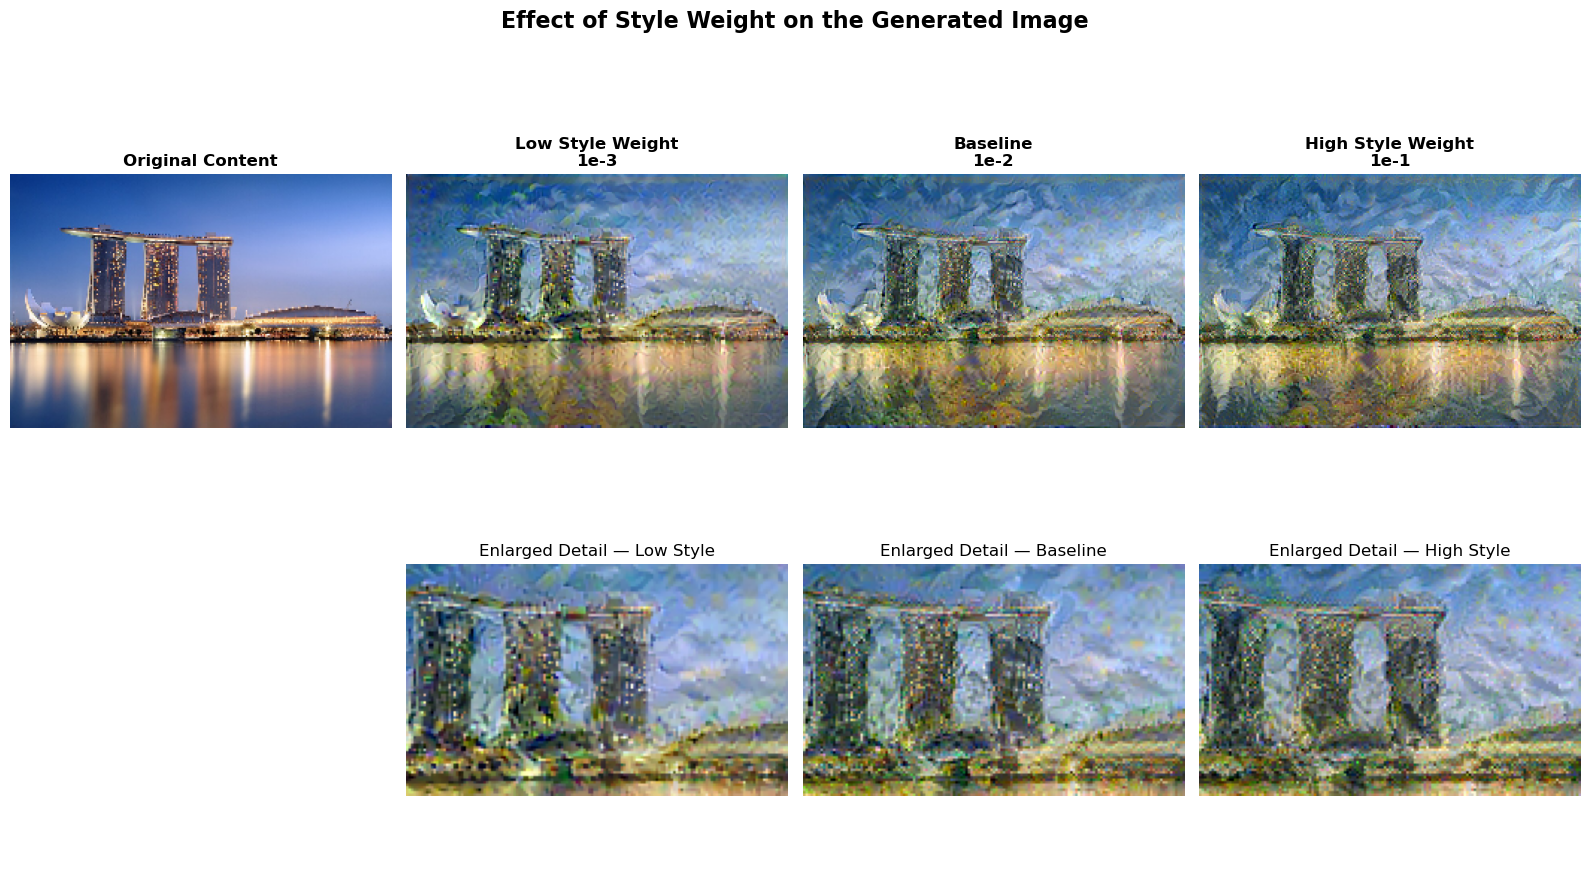

In [12]:
# Load the three saved style-weight outputs
low_style_image = Image.open(result_low_style["output_path"]).convert("RGB")
baseline_image = Image.open(result["output_path"]).convert("RGB")
high_style_image = Image.open(result_high_style["output_path"]).convert("RGB")


# Convert the original content image into PIL format
original_content = tensor_to_image(content_image).convert("RGB")

CROP_REGION = (
    0.20,   # left
    0.15,   # top
    0.80,   # right
    0.70    # bottom
)


def proportional_crop(image, region):
    width, height = image.size

    left = int(region[0] * width)
    top = int(region[1] * height)
    right = int(region[2] * width)
    bottom = int(region[3] * height)

    return image.crop((left, top, right, bottom))


# Create identical crops
low_crop = proportional_crop(low_style_image, CROP_REGION)
baseline_crop = proportional_crop(baseline_image, CROP_REGION)
high_crop = proportional_crop(high_style_image, CROP_REGION)


fig, axes = plt.subplots(
    2,
    4,
    figsize=(16, 9),
    gridspec_kw={"height_ratios": [1.3, 1]}
)


# ORIGINAL CONTENT
axes[0, 0].imshow(original_content)
axes[0, 0].set_title(
    "Original Content",
    fontsize=12,
    fontweight="bold"
)
axes[0, 0].axis("off")


# LOW STYLE
axes[0, 1].imshow(low_style_image)
axes[0, 1].set_title(
    "Low Style Weight\n1e-3",
    fontsize=12,
    fontweight="bold"
)
axes[0, 1].axis("off")


# BASELINE
axes[0, 2].imshow(baseline_image)
axes[0, 2].set_title(
    "Baseline\n1e-2",
    fontsize=12,
    fontweight="bold"
)
axes[0, 2].axis("off")


# HIGH STYLE
axes[0, 3].imshow(high_style_image)
axes[0, 3].set_title(
    "High Style Weight\n1e-1",
    fontsize=12,
    fontweight="bold"
)
axes[0, 3].axis("off")


# First position on second row is intentionally left blank
axes[1, 0].axis("off")

axes[1, 1].imshow(low_crop)
axes[1, 1].set_title("Enlarged Detail — Low Style")
axes[1, 1].axis("off")

axes[1, 2].imshow(baseline_crop)
axes[1, 2].set_title("Enlarged Detail — Baseline")
axes[1, 2].axis("off")

axes[1, 3].imshow(high_crop)
axes[1, 3].set_title("Enlarged Detail — High Style")
axes[1, 3].axis("off")


fig.suptitle(
    "Effect of Style Weight on the Generated Image",
    fontsize=16,
    fontweight="bold"
)

plt.tight_layout()
plt.show()

In [13]:
style_comparison = pd.DataFrame({
    "Setting": [
        "Low Style Weight",
        "Baseline",
        "High Style Weight"
    ],

    "Style Weight": [
        result_low_style["style_weight"],
        result["style_weight"],
        result_high_style["style_weight"]
    ],

    "SSIM": [
        round(result_low_style["ssim_content_score"], 4),
        round(result["ssim_content_score"], 4),
        round(result_high_style["ssim_content_score"], 4)
    ],

    "Runtime (s)": [
        round(result_low_style["runtime_seconds"], 2),
        round(result["runtime_seconds"], 2),
        round(result_high_style["runtime_seconds"], 2)
    ],

    "Style Effect": [
        "Enter observation",
        "Enter observation",
        "Enter observation"
    ],

    "Content Detail": [
        "Enter observation",
        "Enter observation",
        "Enter observation"
    ]
})


display(style_comparison)

,Setting,Style Weight,SSIM,Runtime (s),Style Effect,Content Detail
0,Low Style Weight,0.001,0.4807,161.26,Enter observation,Enter observation
1,Baseline,0.010,0.4002,187.49,Enter observation,Enter observation
2,High Style Weight,0.100,0.3587,156.57,Enter observation,Enter observation


## 13. Experimental Results Summary

In [14]:
# Store the experiments that have already been completed
experiment_results = [
    result,
    result_low_style,
    result_high_style
]

# Descriptions used to make the table easier to read
experiment_metadata = {
    "baseline_run": {
        "experiment": "Baseline",
        "setting": "Baseline"
    },
    "low_style_weight": {
        "experiment": "Style Weight",
        "setting": "Low (1e-3)"
    },
    "high_style_weight": {
        "experiment": "Style Weight",
        "setting": "High (1e-1)"
    }
}


def build_results_table(results):
    rows = []

    for item in results:
        metadata = experiment_metadata.get(
            item["run_id"],
            {
                "experiment": "Other",
                "setting": item["run_id"]
            }
        )

        rows.append({
            "Run ID": item["run_id"],
            "Experiment": metadata["experiment"],
            "Setting": metadata["setting"],
            "Image Size": item["image_size"],
            "Style Weight": item["style_weight"],
            "Content Weight": item["content_weight"],
            "TV Weight": item["total_variation_weight"],
            "Iterations": item["iterations"],
            "Runtime (s)": round(item["runtime_seconds"], 2),
            "SSIM": round(item["ssim_content_score"], 4)
        })

    return pd.DataFrame(rows)


results_df = build_results_table(experiment_results)

display(results_df)

,Run ID,Experiment,Setting,Image Size,Style Weight,Content Weight,TV Weight,Iterations,Runtime (s),SSIM
0,baseline_run,Baseline,Baseline,256,0.010,10000.0,30,300,187.49,0.4002
1,low_style_weight,Style Weight,Low (1e-3),256,0.001,10000.0,30,300,161.26,0.4807
2,high_style_weight,Style Weight,High (1e-1),256,0.100,10000.0,30,300,156.57,0.3587


## 14. Visual and Aesthetic Evaluation

Neural Style Transfer outputs cannot be evaluated using numerical metrics alone. 
Visual and aesthetic assessment is therefore used alongside SSIM, runtime and diagnostic loss values.

Each generated output is assessed using five criteria on a scale from 1 to 5. 
The criteria are considered separately rather than being combined into a single overall score.

### 14.1 Evaluation Criteria

The following criteria are used when reviewing each generated image:

| Criterion | Description |
|---|---|
| Content Preservation | How clearly the structure and main features of the original content image remain visible |
| Style Strength | How clearly the artistic characteristics of the style image are transferred |
| Visual Coherence | How naturally the content and style appear together |
| Artefact Control | How well unwanted distortion, noise or irregular features are avoided |
| Aesthetic Quality | Overall visual appeal of the generated image |

Each criterion is rated from 1 to 5:

- **1** = Very poor
- **2** = Poor
- **3** = Acceptable
- **4** = Good
- **5** = Very good

### 14.2 Evaluation Recording Function

In [15]:
visual_evaluations = {}


def record_visual_evaluation(
    run_id,
    content_preservation,
    style_strength,
    visual_coherence,
    artefact_control,
    aesthetic_quality,
    notes=""
):
    scores = [
        content_preservation,
        style_strength,
        visual_coherence,
        artefact_control,
        aesthetic_quality
    ]

    # Make sure every rating uses the 1–5 scale
    if not all(isinstance(score, (int, float)) and 1 <= score <= 5 for score in scores):
        raise ValueError("All visual evaluation scores must be between 1 and 5.")

    visual_evaluations[run_id] = {
        "Content Preservation": content_preservation,
        "Style Strength": style_strength,
        "Visual Coherence": visual_coherence,
        "Artefact Control": artefact_control,
        "Aesthetic Quality": aesthetic_quality,
        "Notes": notes
    }

    print(f"Visual evaluation recorded for: {run_id}")

### 14.3 Function to Build the Evaluation Table

In [16]:
def build_visual_evaluation_table():
    rows = []

    for run_id, evaluation in visual_evaluations.items():
        row = {
            "Run ID": run_id,
            "Content Preservation": evaluation["Content Preservation"],
            "Style Strength": evaluation["Style Strength"],
            "Visual Coherence": evaluation["Visual Coherence"],
            "Artefact Control": evaluation["Artefact Control"],
            "Aesthetic Quality": evaluation["Aesthetic Quality"],
            "Notes": evaluation["Notes"]
        }

        rows.append(row)

    return pd.DataFrame(rows)


visual_df = build_visual_evaluation_table()

visual_table_display = display(
    visual_df,
    display_id=True
)

,Run ID,Content Preservation,Style Strength,Visual Coherence,Artefact Control,Aesthetic Quality,Notes
0,baseline_run,4,4,4,3,4,The main structure of Marina Bay Sands remains...


In [17]:
def refresh_visual_evaluation_table():
    global visual_df

    visual_df = build_visual_evaluation_table()

    visual_table_display.update(visual_df)

## 15. Controlled Parameter Experiments

The following experiments examine the effect of individual Neural Style Transfer parameters. 
A one-factor-at-a-time approach is used, meaning that only the parameter being investigated 
is changed while the remaining baseline settings stay constant.

### 15.1 Experiment Runner

In [18]:
BASELINE_CONFIG = {
    "image_size": 256,
    "style_weight": 1e-2,
    "content_weight": 1e4,
    "total_variation_weight": 30,
    "iterations": 300
}


def run_controlled_experiment(
    run_id,
    experiment_name,
    setting_label,
    **changes
):
    config = BASELINE_CONFIG.copy()
    config.update(changes)

    generated, result_data, history = run_experiment(
        CONTENT_PATH,
        STYLE_PATH,
        run_id=run_id,
        image_size=config["image_size"],
        style_weight=config["style_weight"],
        content_weight=config["content_weight"],
        total_variation_weight=config["total_variation_weight"],
        iterations=config["iterations"]
    )

    # Replace an existing result if the same Run ID is used again
    experiment_results[:] = [
        item for item in experiment_results
        if item["run_id"] != run_id
    ]

    experiment_results.append(result_data)

    experiment_metadata[run_id] = {
        "experiment": experiment_name,
        "setting": setting_label
    }

    return generated, result_data, history

### 15.2 Content Weight Experiment

This experiment investigates how the strength of content preservation affects the generated output.
The baseline content weight is compared with lower and higher values while all other settings remain fixed.

#### Low content weight

In [19]:
generated_low_content, result_low_content, history_low_content = run_controlled_experiment(
    run_id="low_content_weight",
    experiment_name="Content Weight",
    setting_label="Low (1e3)",
    content_weight=1e3
)

Step 0: total loss = 307494912.00
Step 50: total loss = 5963570.50
Step 100: total loss = 4130761.50
Step 150: total loss = 3509555.50
Step 200: total loss = 3163770.50
Step 250: total loss = 2931830.50


#### High content weight

In [20]:
generated_high_content, result_high_content, history_high_content = run_controlled_experiment(
    run_id="high_content_weight",
    experiment_name="Content Weight",
    setting_label="High (1e5)",
    content_weight=1e5
)

Step 0: total loss = 307494912.00
Step 50: total loss = 40588992.00
Step 100: total loss = 32445462.00
Step 150: total loss = 30010848.00
Step 200: total loss = 29185494.00
Step 250: total loss = 27914884.00


#### Content-Weight comparison

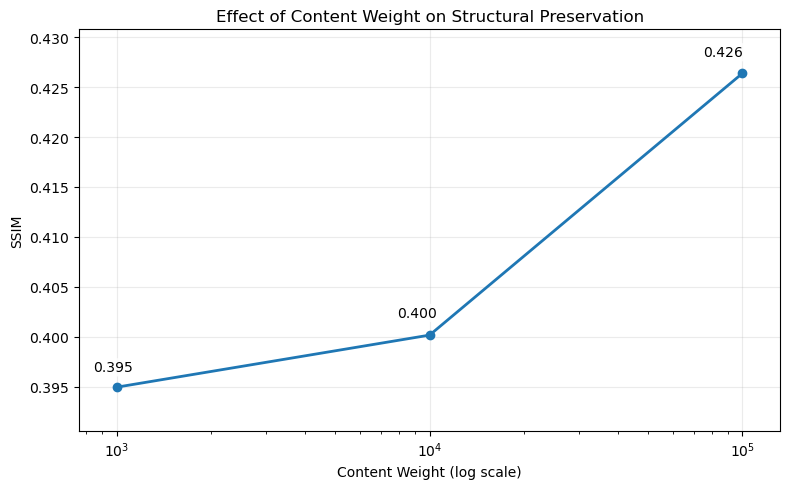

In [21]:
content_results = [
    result_low_content,
    result,
    result_high_content
]

content_weights = [
    item["content_weight"]
    for item in content_results
]

content_ssim = [
    item["ssim_content_score"]
    for item in content_results
]

fig, ax = plt.subplots(figsize=(8, 5))

line, = ax.plot(
    content_weights,
    content_ssim,
    marker="o",
    linewidth=2
)

ax.set_xscale("log")

ax.set_xlabel("Content Weight (log scale)")
ax.set_ylabel("SSIM")
ax.set_title("Effect of Content Weight on Structural Preservation")

ax.grid(alpha=0.25)
ax.margins(x=0.06, y=0.14)

# Draw the graph first so Matplotlib knows the exact screen positions
fig.canvas.draw()

# Convert all data points into screen/display coordinates
display_points = ax.transData.transform(
    np.column_stack((content_weights, content_ssim))
)

axes_box = ax.get_window_extent()

# Marker radius in screen pixels
marker_radius_px = (
    line.get_markersize()
    * fig.dpi
    / 72
    / 2
)

# Padding based automatically on the current font size
font_size = plt.rcParams["font.size"]

padding_px = (
    font_size
    * fig.dpi
    / 72
    * 0.4
)

for i, (weight, score) in enumerate(
    zip(content_weights, content_ssim)
):

    point = display_points[i]

    # Determine the local direction of the plotted line
    if i == 0:
        tangent = (
            display_points[i + 1]
            - display_points[i]
        )

    elif i == len(display_points) - 1:
        tangent = (
            display_points[i]
            - display_points[i - 1]
        )

    else:
        tangent = (
            display_points[i + 1]
            - display_points[i - 1]
        )

    tangent_length = np.linalg.norm(tangent)

    if tangent_length > 0:
        tangent = tangent / tangent_length
    else:
        tangent = np.array([1.0, 0.0])

    # Perpendicular direction away from the line
    normal = np.array([
        -tangent[1],
        tangent[0]
    ])

    # Temporarily create the label so its actual dimensions can be measured
    temporary_text = ax.text(
        weight,
        score,
        f"{score:.3f}",
        ha="center",
        va="center",
        alpha=0
    )

    fig.canvas.draw()

    text_box = temporary_text.get_window_extent(
        renderer=fig.canvas.get_renderer()
    )

    temporary_text.remove()

    # Work out how much space the text requires
    # in the direction perpendicular to the line
    text_clearance = (
        abs(normal[0]) * text_box.width / 2
        +
        abs(normal[1]) * text_box.height / 2
    )

    required_distance = (
        text_clearance
        + marker_radius_px
        + padding_px
    )

    # Try both sides of the line
    candidate_a = (
        point + normal * required_distance
    )

    candidate_b = (
        point - normal * required_distance
    )

    def available_space(candidate):
        return min(
            candidate[0] - axes_box.x0,
            axes_box.x1 - candidate[0],
            candidate[1] - axes_box.y0,
            axes_box.y1 - candidate[1]
        )

    # Automatically choose the side with more space
    if available_space(candidate_b) > available_space(candidate_a):
        normal = -normal

    # Convert pixel distance to Matplotlib offset points
    offset_pixels = normal * required_distance

    offset_points = (
        offset_pixels
        * 72
        / fig.dpi
    )

    ax.annotate(
        f"{score:.3f}",
        xy=(weight, score),
        xytext=(
            offset_points[0],
            offset_points[1]
        ),
        textcoords="offset points",
        ha="center",
        va="center",
        bbox=dict(
            boxstyle="round,pad=0.15",
            facecolor="white",
            edgecolor="none",
            alpha=0.85
        )
    )

plt.tight_layout()
plt.show()

### 15.3 Iteration Experiment

This experiment examines whether additional optimisation iterations produce a noticeable 
improvement in the stylised output and whether the improvement justifies the additional runtime.

#### 100 iterations

In [22]:
generated_100_iterations, result_100_iterations, history_100_iterations = run_controlled_experiment(
    run_id="iterations_100",
    experiment_name="Iterations",
    setting_label="100 Iterations",
    iterations=100
)

Step 0: total loss = 307494912.00
Step 50: total loss = 13935715.00


#### 500 iterations

In [23]:
generated_500_iterations, result_500_iterations, history_500_iterations = run_controlled_experiment(
    run_id="iterations_500",
    experiment_name="Iterations",
    setting_label="500 Iterations",
    iterations=500
)

Step 0: total loss = 307494912.00
Step 50: total loss = 13935715.00
Step 100: total loss = 10413094.00
Step 150: total loss = 9150015.00
Step 200: total loss = 8479672.00
Step 250: total loss = 8065293.00
Step 300: total loss = 7779628.50
Step 350: total loss = 7563812.00
Step 400: total loss = 7414932.00
Step 450: total loss = 7260404.50


#### Iterations comparision

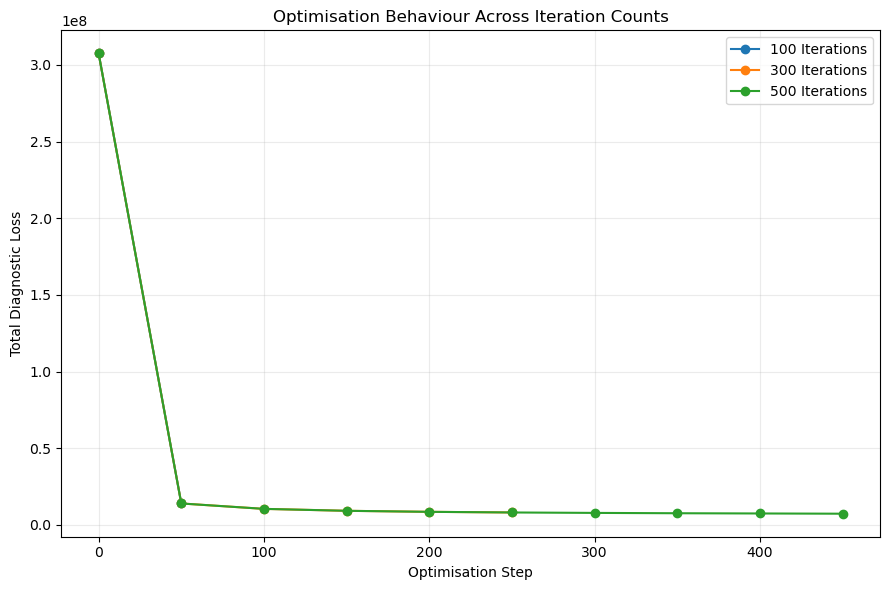

In [24]:
def extract_loss_curve(history):
    steps = [item["step"] for item in history]
    losses = [item["total_loss"] for item in history]

    return steps, losses


steps_100, losses_100 = extract_loss_curve(history_100_iterations)
steps_300, losses_300 = extract_loss_curve(loss_history)
steps_500, losses_500 = extract_loss_curve(history_500_iterations)


plt.figure(figsize=(9, 6))

plt.plot(
    steps_100,
    losses_100,
    marker="o",
    label="100 Iterations"
)

plt.plot(
    steps_300,
    losses_300,
    marker="o",
    label="300 Iterations"
)

plt.plot(
    steps_500,
    losses_500,
    marker="o",
    label="500 Iterations"
)

plt.xlabel("Optimisation Step")
plt.ylabel("Total Diagnostic Loss")
plt.title("Optimisation Behaviour Across Iteration Counts")

plt.legend()
plt.grid(alpha=0.25)
plt.tight_layout()
plt.show()

### 15.4 Image Resolution Experiment

This experiment evaluates the relationship between image resolution, visual detail and processing time.

#### 384 pixels

In [25]:
generated_384, result_384, history_384 = run_controlled_experiment(
    run_id="image_size_384",
    experiment_name="Image Size",
    setting_label="384 Pixels",
    image_size=384
)

Step 0: total loss = 190856864.00
Step 50: total loss = 9415926.00
Step 100: total loss = 6875309.50
Step 150: total loss = 6067295.00
Step 200: total loss = 5628213.50
Step 250: total loss = 5351937.50


#### 512 pixels

In [26]:
generated_512, result_512, history_512 = run_controlled_experiment(
    run_id="image_size_512",
    experiment_name="Image Size",
    setting_label="512 Pixels",
    image_size=512
)

Step 0: total loss = 148267152.00
Step 50: total loss = 7403851.00
Step 100: total loss = 5393055.00
Step 150: total loss = 4702280.00
Step 200: total loss = 4358966.00
Step 250: total loss = 4106712.00


#### Pixels comparision

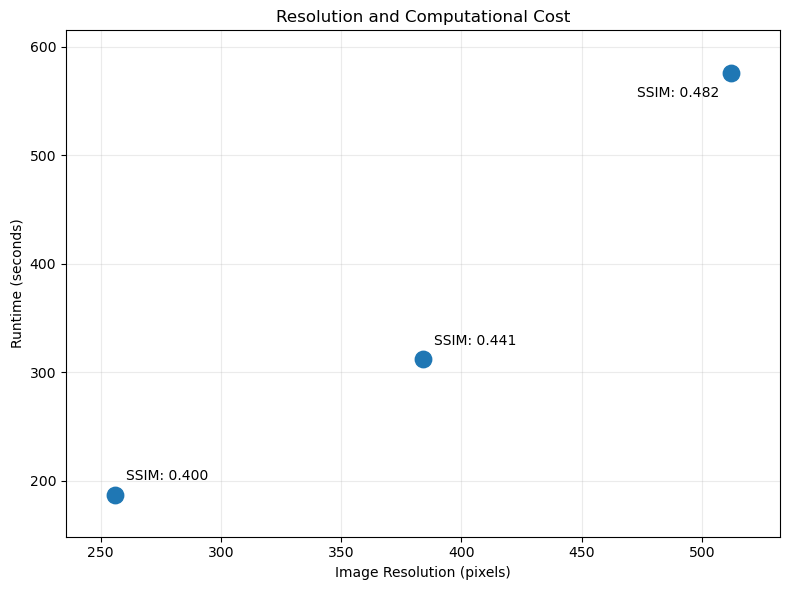

In [27]:
resolution_results = [
    result,
    result_384,
    result_512
]

resolutions = [
    item["image_size"]
    for item in resolution_results
]

resolution_runtime = [
    item["runtime_seconds"]
    for item in resolution_results
]

resolution_ssim = [
    item["ssim_content_score"]
    for item in resolution_results
]

fig, ax = plt.subplots(figsize=(8, 6))

ax.scatter(
    resolutions,
    resolution_runtime,
    s=140
)

# Work out the data ranges automatically
x_min = min(resolutions)
x_max = max(resolutions)
y_min = min(resolution_runtime)
y_max = max(resolution_runtime)

x_range = x_max - x_min
y_range = y_max - y_min

for size, runtime, score in zip(
    resolutions,
    resolution_runtime,
    resolution_ssim
):
    # Check whether the point is near the right edge
    near_right = (
        x_range > 0 and
        size > x_min + 0.8 * x_range
    )

    # Check whether the point is near the top edge
    near_top = (
        y_range > 0 and
        runtime > y_min + 0.8 * y_range
    )

    # Automatically choose label direction
    x_offset = -8 if near_right else 8
    y_offset = -10 if near_top else 8

    horizontal_alignment = "right" if near_right else "left"
    vertical_alignment = "top" if near_top else "bottom"

    ax.annotate(
        f"SSIM: {score:.3f}",
        xy=(size, runtime),
        xytext=(x_offset, y_offset),
        textcoords="offset points",
        ha=horizontal_alignment,
        va=vertical_alignment
    )

ax.set_xlabel("Image Resolution (pixels)")
ax.set_ylabel("Runtime (seconds)")
ax.set_title("Resolution and Computational Cost")

# Give the plot some automatic breathing space
ax.margins(x=0.08, y=0.10)

ax.grid(alpha=0.25)

plt.tight_layout()
plt.show()

### 15.5 Total Variation Weight Experiment

This experiment investigates how total variation regularisation affects image smoothness and visible artefacts.

#### Low TV weight

In [28]:
generated_low_tv, result_low_tv, history_low_tv = run_controlled_experiment(
    run_id="low_tv_weight",
    experiment_name="Total Variation Weight",
    setting_label="Low (10)",
    total_variation_weight=10
)

Step 0: total loss = 307311264.00
Step 50: total loss = 13553783.00
Step 100: total loss = 10062981.00
Step 150: total loss = 8801487.00
Step 200: total loss = 8141195.50
Step 250: total loss = 7751128.00


#### High TV weight

In [29]:
generated_high_tv, result_high_tv, history_high_tv = run_controlled_experiment(
    run_id="high_tv_weight",
    experiment_name="Total Variation Weight",
    setting_label="High (100)",
    total_variation_weight=100
)

Step 0: total loss = 308137632.00
Step 50: total loss = 15158370.00
Step 100: total loss = 11509388.00
Step 150: total loss = 10092992.00
Step 200: total loss = 9348646.00
Step 250: total loss = 8887125.00


#### TV weight comparision

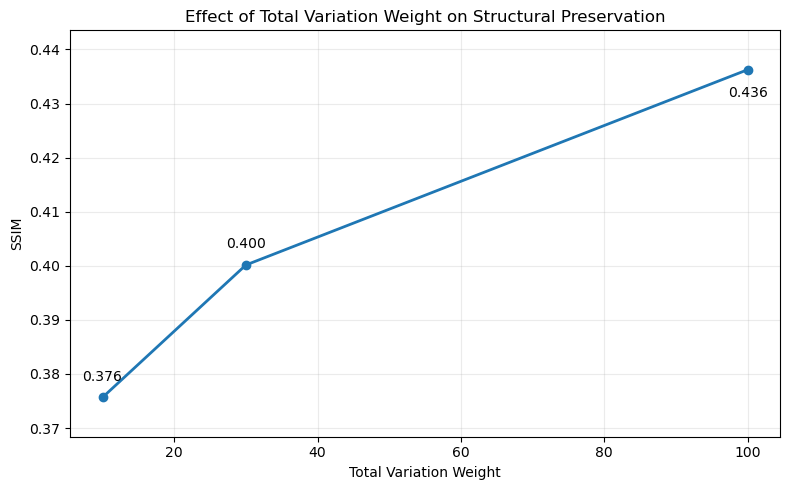

In [30]:
tv_results = [
    result_low_tv,
    result,
    result_high_tv
]

tv_weights = [
    item["total_variation_weight"]
    for item in tv_results
]

tv_ssim = [
    item["ssim_content_score"]
    for item in tv_results
]

fig, ax = plt.subplots(figsize=(8, 5))

ax.plot(
    tv_weights,
    tv_ssim,
    marker="o",
    linewidth=2
)

# Calculate the SSIM range automatically
y_min = min(tv_ssim)
y_max = max(tv_ssim)
y_range = y_max - y_min

for weight, score in zip(tv_weights, tv_ssim):

    # If a point is close to the top of the graph,
    # place its label below the marker instead.
    if y_range > 0 and score > y_min + (0.8 * y_range):
        offset = (0, -12)
        vertical_alignment = "top"
    else:
        offset = (0, 10)
        vertical_alignment = "bottom"

    ax.annotate(
        f"{score:.3f}",
        xy=(weight, score),
        xytext=offset,
        textcoords="offset points",
        ha="center",
        va=vertical_alignment
    )

ax.set_xlabel("Total Variation Weight")
ax.set_ylabel("SSIM")
ax.set_title(
    "Effect of Total Variation Weight on Structural Preservation"
)

# Add automatic vertical spacing
ax.margins(y=0.12)

ax.grid(alpha=0.25)

plt.tight_layout()
plt.show()

### 15.6 Artistic Style Comparison

This experiment applies the same baseline configuration to several artistic style images. The original baseline style is reused as Style 1, while additional images are loaded automatically from the `style_images` folder. Up to four styles are compared.


In [31]:
STYLE_DIRECTORY = Path("style_images")
SUPPORTED_EXTENSIONS = {".jpg", ".jpeg", ".png", ".bmp", ".webp"}
MAX_STYLES = 4

# Find all available style images.
available_style_paths = sorted(
    [
        path
        for path in STYLE_DIRECTORY.iterdir()
        if path.is_file() and path.suffix.lower() in SUPPORTED_EXTENSIONS
    ]
)

primary_style_path = Path(STYLE_PATH)

if not primary_style_path.exists():
    raise FileNotFoundError(
        f"Primary style image not found: {STYLE_PATH}"
    )

# Keep the original baseline style first.
other_style_paths = [
    path
    for path in available_style_paths
    if path.resolve() != primary_style_path.resolve()
]

selected_style_paths = [primary_style_path] + other_style_paths
selected_style_paths = selected_style_paths[:MAX_STYLES]

if len(selected_style_paths) < MAX_STYLES:
    print(
        f"Found {len(selected_style_paths)} style image(s). "
        f"Add more images to '{STYLE_DIRECTORY}' for a {MAX_STYLES}-style comparison."
    )

# Store outputs in lists instead of separate variables such as
# style2_output, style3_output and style4_output.
# This prevents undefined-variable NameError problems.
multi_style_outputs = []
multi_style_results = []

# Style 1 uses the baseline run that has already been completed.
multi_style_outputs.append({
    "style_number": 1,
    "style_name": primary_style_path.stem,
    "style_path": str(primary_style_path),
    "run_id": result["run_id"],
    "generated": generated_image,
    "result": result
})

multi_style_results.append({
    "style_number": 1,
    "style_name": primary_style_path.stem,
    "style_path": str(primary_style_path),
    "run_id": result["run_id"],
    "result": result
})

# Generate additional styles using exactly the baseline settings.
for style_number, style_path in enumerate(selected_style_paths[1:], start=2):
    run_id = f"style_comparison_{style_number}"

    generated_style, style_result, style_history = run_experiment(
        CONTENT_PATH,
        str(style_path),
        run_id=run_id,
        image_size=BASELINE_CONFIG["image_size"],
        style_weight=BASELINE_CONFIG["style_weight"],
        content_weight=BASELINE_CONFIG["content_weight"],
        total_variation_weight=BASELINE_CONFIG["total_variation_weight"],
        iterations=BASELINE_CONFIG["iterations"]
    )

    # Replace any older copy of the same run before appending.
    experiment_results[:] = [
        item for item in experiment_results
        if item["run_id"] != run_id
    ]
    experiment_results.append(style_result)

    experiment_metadata[run_id] = {
        "experiment": "Artistic Style",
        "setting": f"Style {style_number}: {style_path.stem}"
    }

    multi_style_outputs.append({
        "style_number": style_number,
        "style_name": style_path.stem,
        "style_path": str(style_path),
        "run_id": run_id,
        "generated": generated_style,
        "result": style_result
    })

    multi_style_results.append({
        "style_number": style_number,
        "style_name": style_path.stem,
        "style_path": str(style_path),
        "run_id": run_id,
        "result": style_result
    })

print(f"Multi-style comparison prepared with {len(multi_style_outputs)} style image(s).")


Step 0: total loss = 383343360.00
Step 50: total loss = 15011655.00
Step 100: total loss = 11329926.00
Step 150: total loss = 10059528.00
Step 200: total loss = 9337578.00
Step 250: total loss = 8837670.00
Step 0: total loss = 382706144.00
Step 50: total loss = 20301718.00
Step 100: total loss = 14799005.00
Step 150: total loss = 13006342.00
Step 200: total loss = 11986258.00
Step 250: total loss = 11332613.00
Step 0: total loss = 174712240.00
Step 50: total loss = 22134088.00
Step 100: total loss = 16767828.00
Step 150: total loss = 14688169.00
Step 200: total loss = 13570393.00
Step 250: total loss = 12961122.00
Multi-style comparison prepared with 4 style image(s).


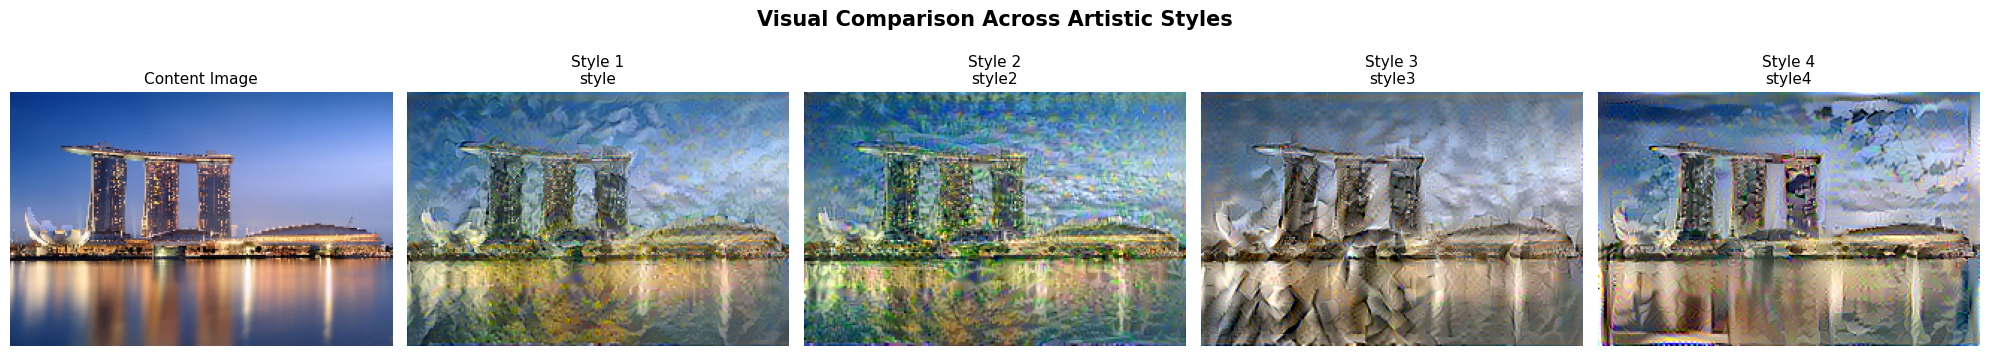

In [32]:
# MULTI-STYLE VISUAL COMPARISON GRID

display_items = [
    ("Content Image", content_image)
]

for item in multi_style_outputs:
    display_items.append(
        (
            f"Style {item['style_number']}\n{item['style_name']}",
            item["generated"]
        )
    )

fig, axes = plt.subplots(
    1,
    len(display_items),
    figsize=(4 * len(display_items), 4)
)

# Make axes iterable even when only one image is available.
axes = np.atleast_1d(axes)

for ax, (title, image) in zip(axes, display_items):
    ax.imshow(tensor_to_image(image))
    ax.set_title(title, fontsize=11)
    ax.axis("off")

fig.suptitle(
    "Visual Comparison Across Artistic Styles",
    fontsize=15,
    fontweight="bold"
)

plt.tight_layout()
plt.show()


### 15.7 Update the complete results table


In [33]:
results_df = build_results_table(experiment_results)

display(results_df)

,Run ID,Experiment,Setting,Image Size,Style Weight,Content Weight,TV Weight,Iterations,Runtime (s),SSIM
0,baseline_run,Baseline,Baseline,256,0.010,10000.0,30,300,187.49,0.4002
1,low_style_weight,Style Weight,Low (1e-3),256,0.001,10000.0,30,300,161.26,0.4807
2,high_style_weight,Style Weight,High (1e-1),256,0.100,10000.0,30,300,156.57,0.3587
3,low_content_weight,Content Weight,Low (1e3),256,0.010,1000.0,30,300,148.68,0.3949
4,high_content_weight,Content Weight,High (1e5),256,0.010,100000.0,30,300,152.66,0.4264
5,iterations_100,Iterations,100 Iterations,256,0.010,10000.0,30,100,51.33,0.3927
6,iterations_500,Iterations,500 Iterations,256,0.010,10000.0,30,500,253.02,0.3887
7,image_size_384,Image Size,384 Pixels,384,0.010,10000.0,30,300,312.00,0.4412
8,image_size_512,Image Size,512 Pixels,512,0.010,10000.0,30,300,576.44,0.4817
9,low_tv_weight,Total Variation Weight,Low (10),256,0.010,10000.0,10,300,140.41,0.3757


### 15.8 Record Visual Evaluation Results


In [34]:
record_visual_evaluation(
    run_id="baseline_run",
    content_preservation=4,
    style_strength=4,
    visual_coherence=4,
    artefact_control=3,
    aesthetic_quality=4,
    notes="The main structure of Marina Bay Sands remains clearly recognisable while the artistic texture and colour are transferred effectively. Some fine architectural details and edges appear softened or slightly distorted."
)

Visual evaluation recorded for: baseline_run


In [35]:
refresh_visual_evaluation_table()

## 16. Quantitative Results Visualisation

### Runtime comparison

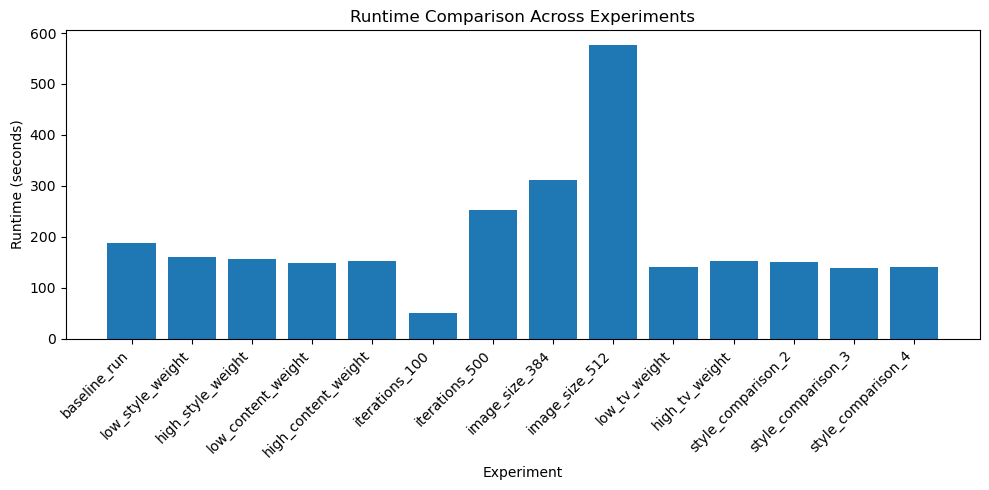

In [36]:
results_df = build_results_table(experiment_results)

plt.figure(figsize=(10, 5))

plt.bar(
    results_df["Run ID"],
    results_df["Runtime (s)"]
)

plt.xlabel("Experiment")
plt.ylabel("Runtime (seconds)")
plt.title("Runtime Comparison Across Experiments")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()

### SSIM comparison

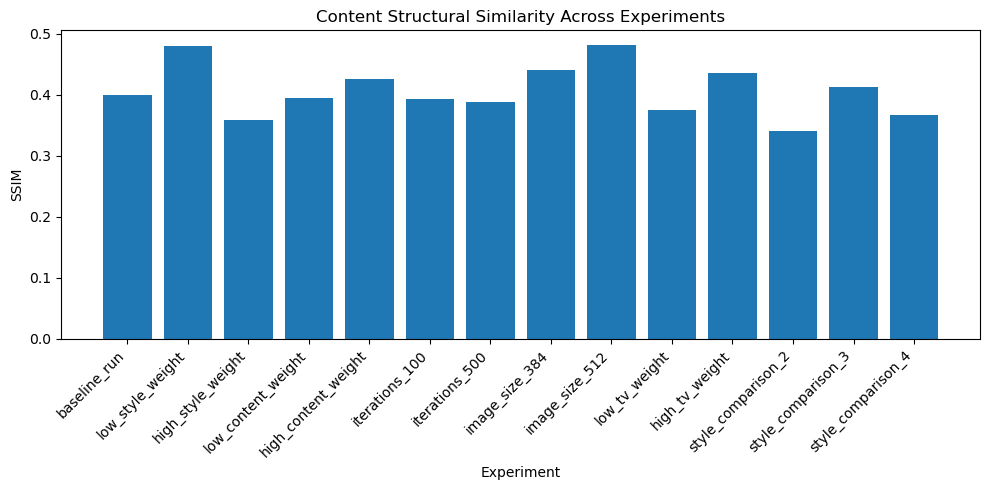

In [37]:
plt.figure(figsize=(10, 5))

plt.bar(
    results_df["Run ID"],
    results_df["SSIM"]
)

plt.xlabel("Experiment")
plt.ylabel("SSIM")
plt.title("Content Structural Similarity Across Experiments")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()

## 17. Final Experiment Comparison

This section brings together quantitative results and visual evaluation evidence. 
The final configuration is selected by considering the individual trade-offs between content preservation, 
style strength, visual quality, artefacts and runtime rather than using a single combined score.

In [38]:
results_df = build_results_table(experiment_results)

visual_df = build_visual_evaluation_table()

if not visual_df.empty:
    final_results_df = results_df.merge(
        visual_df,
        on="Run ID",
        how="left"
    )
else:
    final_results_df = results_df.copy()

display(final_results_df)

,Run ID,Experiment,Setting,Image Size,Style Weight,Content Weight,TV Weight,Iterations,Runtime (s),SSIM,Content Preservation,Style Strength,Visual Coherence,Artefact Control,Aesthetic Quality,Notes
0,baseline_run,Baseline,Baseline,256,0.010,10000.0,30,300,187.49,0.4002,4.0,4.0,4.0,3.0,4.0,The main structure of Marina Bay Sands remains...
1,low_style_weight,Style Weight,Low (1e-3),256,0.001,10000.0,30,300,161.26,0.4807,NaN,NaN,NaN,NaN,NaN,NaN
2,high_style_weight,Style Weight,High (1e-1),256,0.100,10000.0,30,300,156.57,0.3587,NaN,NaN,NaN,NaN,NaN,NaN
3,low_content_weight,Content Weight,Low (1e3),256,0.010,1000.0,30,300,148.68,0.3949,NaN,NaN,NaN,NaN,NaN,NaN
4,high_content_weight,Content Weight,High (1e5),256,0.010,100000.0,30,300,152.66,0.4264,NaN,NaN,NaN,NaN,NaN,NaN
5,iterations_100,Iterations,100 Iterations,256,0.010,10000.0,30,100,51.33,0.3927,NaN,NaN,NaN,NaN,NaN,NaN
6,iterations_500,Iterations,500 Iterations,256,0.010,10000.0,30,500,253.02,0.3887,NaN,NaN,NaN,NaN,NaN,NaN
7,image_size_384,Image Size,384 Pixels,384,0.010,10000.0,30,300,312.00,0.4412,NaN,NaN,NaN,NaN,NaN,NaN
8,image_size_512,Image Size,512 Pixels,512,0.010,10000.0,30,300,576.44,0.4817,NaN,NaN,NaN,NaN,NaN,NaN
9,low_tv_weight,Total Variation Weight,Low (10),256,0.010,10000.0,10,300,140.41,0.3757,NaN,NaN,NaN,NaN,NaN,NaN


### Multi-Style Comparison

The table below summarises quantitative results and available visual ratings for the artistic style comparison. Blank visual ratings indicate that a visual score has not yet been recorded for that style.


In [39]:
# MULTI-STYLE COMPARISON TABLE


if "multi_style_results" not in globals() or len(multi_style_results) == 0:
    print("Run Section 15.6 Artistic Style Comparison first.")
else:
    multi_style_rows = []

    for item in multi_style_results:
        style_result = item["result"]
        run_id = item["run_id"]

        # Use recorded visual scores when available.
        visual = visual_evaluations.get(run_id, {})

        multi_style_rows.append({
            "Style": f"Style {item['style_number']}",
            "Style Image": item["style_name"],
            "SSIM": round(style_result["ssim_content_score"], 4),
            "Runtime (s)": round(style_result["runtime_seconds"], 2),
            "Content Preservation": visual.get("Content Preservation", np.nan),
            "Style Strength": visual.get("Style Strength", np.nan),
            "Visual Coherence": visual.get("Visual Coherence", np.nan),
            "Artefact Control": visual.get("Artefact Control", np.nan),
            "Aesthetic Quality": visual.get("Aesthetic Quality", np.nan)
        })

    multi_style_comparison_df = pd.DataFrame(multi_style_rows)

    display(multi_style_comparison_df)


,Style,Style Image,SSIM,Runtime (s),Content Preservation,Style Strength,Visual Coherence,Artefact Control,Aesthetic Quality
0,Style 1,style,0.4002,187.49,4.0,4.0,4.0,3.0,4.0
1,Style 2,style2,0.3411,150.00,NaN,NaN,NaN,NaN,NaN
2,Style 3,style3,0.4133,138.14,NaN,NaN,NaN,NaN,NaN
3,Style 4,style4,0.3665,140.63,NaN,NaN,NaN,NaN,NaN


In [40]:
SELECTED_RUN_ID = "baseline_run"   # Change after completing the evaluation


selected_result = next(
    item for item in experiment_results
    if item["run_id"] == SELECTED_RUN_ID
)


selected_summary = pd.DataFrame({
    "Measure": [
        "Selected Run",
        "Image Size",
        "Style Weight",
        "Content Weight",
        "TV Weight",
        "Iterations",
        "Runtime (seconds)",
        "SSIM"
    ],
    "Value": [
        selected_result["run_id"],
        selected_result["image_size"],
        selected_result["style_weight"],
        selected_result["content_weight"],
        selected_result["total_variation_weight"],
        selected_result["iterations"],
        round(selected_result["runtime_seconds"], 2),
        round(selected_result["ssim_content_score"], 4)
    ]
})

display(selected_summary)

,Measure,Value
0,Selected Run,baseline_run
1,Image Size,256
2,Style Weight,0.01
3,Content Weight,10000.0
4,TV Weight,30
5,Iterations,300
6,Runtime (seconds),187.49
7,SSIM,0.4002


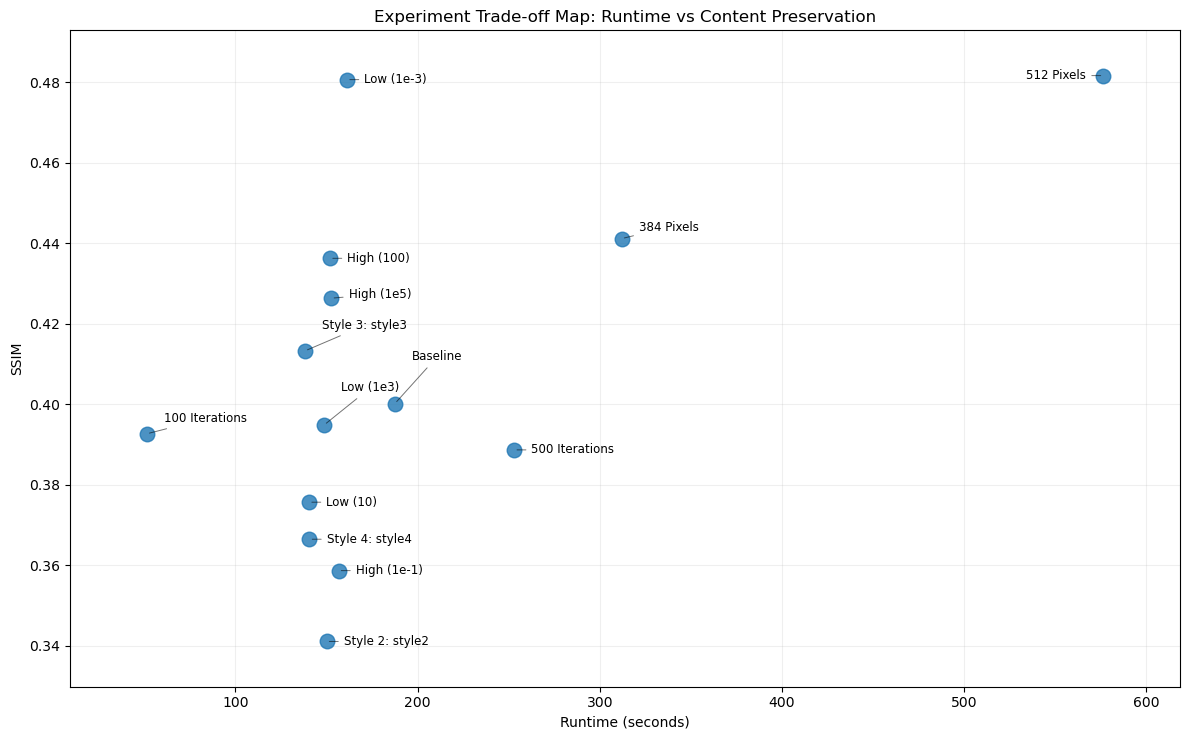

In [42]:
results_df = build_results_table(experiment_results)

fig, ax = plt.subplots(figsize=(12, 7.5))

x_values = results_df["Runtime (s)"].to_numpy()
y_values = results_df["SSIM"].to_numpy()
labels = results_df["Setting"].astype(str).to_list()

# Plot experiment points
ax.scatter(
    x_values,
    y_values,
    s=110,
    alpha=0.8,
    zorder=3
)

x_min, x_max = x_values.min(), x_values.max()
y_min, y_max = y_values.min(), y_values.max()

x_range = max(x_max - x_min, 1)
y_range = max(y_max - y_min, 0.01)

# Add space around the graph before positioning labels
ax.set_xlim(
    x_min - (0.08 * x_range),
    x_max + (0.08 * x_range)
)

ax.set_ylim(
    y_min - (0.08 * y_range),
    y_max + (0.08 * y_range)
)

# Split labels automatically depending on position in the graph
x_midpoint = (x_min + x_max) / 2

left_group = []
right_group = []

for x, y, label in zip(x_values, y_values, labels):

    # Labels for points on the right side are placed to the left.
    # Labels for remaining points are placed to the right.
    if x > x_midpoint:
        right_group.append((x, y, label))
    else:
        left_group.append((x, y, label))


def spread_labels(points, side="right"):
    """
    Automatically spreads labels vertically to avoid overlap.
    Label positions are calculated from the data rather than
    manually assigned to individual experiments.
    """

    if not points:
        return

    # Sort according to SSIM value
    points = sorted(points, key=lambda item: item[1])

    preferred_y = [item[1] for item in points]

    # Minimum vertical spacing between labels
    min_spacing = y_range * 0.055

    adjusted_y = preferred_y.copy()

    # Forward pass: separate labels that are too close
    for i in range(1, len(adjusted_y)):
        if adjusted_y[i] - adjusted_y[i - 1] < min_spacing:
            adjusted_y[i] = adjusted_y[i - 1] + min_spacing

    # Keep labels inside graph boundaries
    lower_limit = ax.get_ylim()[0] + y_range * 0.02
    upper_limit = ax.get_ylim()[1] - y_range * 0.02

    # Shift group down if highest label exceeds graph
    if adjusted_y[-1] > upper_limit:
        difference = adjusted_y[-1] - upper_limit
        adjusted_y = [value - difference for value in adjusted_y]

    # Backward pass if lower labels become too close
    for i in range(len(adjusted_y) - 2, -1, -1):
        if adjusted_y[i + 1] - adjusted_y[i] < min_spacing:
            adjusted_y[i] = adjusted_y[i + 1] - min_spacing

    # Shift group upwards if required
    if adjusted_y[0] < lower_limit:
        difference = lower_limit - adjusted_y[0]
        adjusted_y = [value + difference for value in adjusted_y]

    for (x, original_y, label), text_y in zip(points, adjusted_y):

        if side == "right":
            text_x = x + (x_range * 0.018)
            horizontal_alignment = "left"
        else:
            text_x = x - (x_range * 0.018)
            horizontal_alignment = "right"

        ax.annotate(
            label,
            xy=(x, original_y),
            xytext=(text_x, text_y),
            textcoords="data",
            ha=horizontal_alignment,
            va="center",
            fontsize=8.5,
            arrowprops=dict(
                arrowstyle="-",
                linewidth=0.7,
                alpha=0.55
            ),
            zorder=4
        )


# Apply automatic positioning
spread_labels(left_group, side="right")
spread_labels(right_group, side="left")

ax.set_xlabel("Runtime (seconds)")
ax.set_ylabel("SSIM")

ax.set_title(
    "Experiment Trade-off Map: Runtime vs Content Preservation"
)

ax.grid(alpha=0.2)

plt.tight_layout()
plt.show()